# 01 · Data loading and quality checks

**Project 7: Remaining Useful Life (RUL) prediction for industrial engines** (Phase 1, classical ML)

This notebook loads the FD001 subset of NASA's C-MAPSS data, checks that it is complete and consistent, decides which columns are worth keeping, and builds the RUL target. Everything after this builds on what is verified here.

| # | Notebook | What it does |
|---|---|---|
| **01** | **Data loading & quality** | load FD001, column dictionary, quality checks, flat columns, RUL labels |
| 02 | Exploratory analysis | lifetimes, operating conditions, sensor degradation, sensor ranking, target design |
| 03 | Feature engineering | regime normalisation, rolling / slope / baseline / health-index features, leakage test |
| 04 | Model training & validation | engine-level CV, target and feature ablations, Elastic Net / RF / XGBoost tuning |
| 05 | Test evaluation & error analysis | official test set, early vs late degradation error, SHAP, where the baseline falls short |

In [1]:
import sys
from pathlib import Path

# Make the project folder importable (works from notebooks/ locally and on Colab)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import SENSOR_INFO, SENSOR_COLS, SETTING_COLS, USEFUL_SENSORS
from src.data import load_cmapss, add_train_rul, add_test_rul
from src.plotting import set_style, save, BLUE, ORANGE, GREY

set_style()
pd.set_option("display.precision", 4)

## 1. About the data

C-MAPSS (Commercial Modular Aero-Propulsion System Simulation) is NASA's simulator of a large commercial turbofan engine. Saxena et al. (2008) used it to generate run-to-failure histories. Every engine starts with a different, unknown amount of initial wear and manufacturing variation. It runs normally for a while, then a fault appears and grows until the engine fails.

FD001 is the simplest of the four subsets:

- **one operating condition** (sea level) and **one fault mode** (High-Pressure Compressor degradation)
- **100 training engines**, each observed from the start until failure
- **100 test engines**, stopped at some point before failure; `RUL_FD001.txt` gives the true RUL at the last observed cycle

Each row is one engine during one operating cycle (one flight): engine id, cycle number, three operational settings and 21 sensor readings. The files have no header, so column names are assigned in `src/data.py`. If the files are not in `data/raw/`, they are downloaded from the NASA PCoE mirror automatically.

In [2]:
train, test, rul = load_cmapss("FD001")

print(f"train      : {train.shape[0]:>6,} rows x {train.shape[1]} columns")
print(f"test       : {test.shape[0]:>6,} rows x {test.shape[1]} columns")
print(f"RUL labels : {len(rul):>6} values (one per test engine)")
train.head()

train      : 20,631 rows x 26 columns
test       : 13,096 rows x 26 columns
RUL labels :    100 values (one per test engine)


,unit,cycle,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


The sensors are documented in Table 2 of Saxena et al. (2008). The raw files only number them, so here is the mapping we use throughout the project:

In [3]:
sensor_table = pd.DataFrame(
    [(col, *SENSOR_INFO[col]) for col in SENSOR_COLS],
    columns=["column", "symbol", "description", "unit"],
).set_index("column")
sensor_table

,symbol,description,unit
column,,,
s_1,T2,Total temperature at fan inlet,°R
s_2,T24,Total temperature at LPC outlet,°R
s_3,T30,Total temperature at HPC outlet,°R
s_4,T50,Total temperature at LPT outlet,°R
s_5,P2,Pressure at fan inlet,psia
s_6,P15,Total pressure in bypass duct,psia
s_7,P30,Total pressure at HPC outlet,psia
s_8,Nf,Physical fan speed,rpm
s_9,Nc,Physical core speed,rpm


## 2. Structure: engines and cycles

In [4]:
def life_summary(df):
    cycles = df.groupby("unit")["cycle"].max()
    return {"engines": df["unit"].nunique(), "rows": len(df),
            "min cycles": cycles.min(), "mean cycles": round(cycles.mean(), 1),
            "max cycles": cycles.max()}

pd.DataFrame([life_summary(train), life_summary(test)],
             index=["train (run to failure)", "test (cut before failure)"])

,engines,rows,min cycles,mean cycles,max cycles
train (run to failure),100,20631,128,206.3,362
test (cut before failure),100,13096,31,131.0,303


Training engines last between 128 and 362 cycles, so lifetimes vary by almost a factor of three. Engine age alone cannot tell us how close an engine is to failure. The test engines are stopped much earlier (after 31 to 303 cycles), which is what a model would face in service: it sees a partial history and has to estimate what is left.

## 3. Data-quality checks

We check for the usual problems (missing values, duplicates) and for things specific to time-series data: every engine should start at cycle 1, have no gaps, and the test labels must line up with the test engines.

In [5]:
def quality_checks(df):
    cyc = df.groupby("unit")["cycle"]
    return {
        "missing values": int(df.isna().sum().sum()),
        "infinite values": int(np.isinf(df.select_dtypes("number")).sum().sum()),
        "duplicate rows": int(df.duplicated().sum()),
        "duplicate (unit, cycle) pairs": int(df.duplicated(["unit", "cycle"]).sum()),
        "engines not starting at cycle 1": int((cyc.min() != 1).sum()),
        "engines with gaps in cycles": int((cyc.max() != cyc.count()).sum()),
        "engine ids are 1..100": bool(sorted(df["unit"].unique()) == list(range(1, 101))),
    }

checks = pd.DataFrame({"train": quality_checks(train), "test": quality_checks(test)})
checks.loc["RUL labels match test engines", "test"] = len(rul) == test["unit"].nunique()
checks.loc["negative RUL labels", "test"] = int((rul < 0).sum())
checks.fillna("-")

,train,test
missing values,0,0
infinite values,0,0
duplicate rows,0,0
"duplicate (unit, cycle) pairs",0,0
engines not starting at cycle 1,0,0
engines with gaps in cycles,0,0
engine ids are 1..100,True,True
RUL labels match test engines,-,True
negative RUL labels,-,0


The data is clean: no missing or duplicated values, and every engine has a complete, gap-free sequence of cycles starting at 1. No imputation or row removal is needed. This is expected for simulated data, but it is still worth confirming before relying on it, especially since the per-engine rolling features in notebook 03 assume consecutive cycles.

## 4. Constant and near-constant columns

A column that never changes carries no information about degradation. We look at the spread and the number of distinct values of every setting and sensor in the training data.

In [6]:
spread = pd.DataFrame({
    "std": train[SETTING_COLS + SENSOR_COLS].std(),
    "distinct values": train[SETTING_COLS + SENSOR_COLS].nunique(),
})
spread["symbol"] = [SENSOR_INFO.get(c, ("setting",))[0] for c in spread.index]
spread.sort_values("distinct values").head(10)

,std,distinct values,symbol
s_18,0.0000e+00,1,Nf_dmd
setting_3,0.0000e+00,1,setting
s_1,0.0000e+00,1,T2
s_16,3.4695e-18,1,farB
s_19,0.0000e+00,1,PCNfR_dmd
s_10,0.0000e+00,1,epr
s_5,5.3292e-15,1,P2
s_6,1.3890e-03,2,P15
setting_2,2.9306e-04,13,setting
s_17,1.5488e+00,13,htBleed


- `s_1`, `s_5`, `s_10`, `s_16`, `s_18`, `s_19` and `setting_3` take a **single value** in all 20,631 rows. They are dropped.
- `s_6` (bypass-duct pressure) only takes **two values** (21.60 and 21.61). That is a rounding artefact rather than a signal, and notebook 02 confirms it has no trend. It is dropped too.
- `setting_1` and `setting_2` vary, but only as tiny noise around zero (std of about 0.002 and 0.0003). FD001 has one operating condition, so the settings are not used as inputs. Notebook 02 shows this visually and compares it with FD002, where the settings do matter.

That leaves **14 sensors**:

In [7]:
sensor_table.loc[USEFUL_SENSORS, ["symbol", "description"]]

,symbol,description
column,,
s_2,T24,Total temperature at LPC outlet
s_3,T30,Total temperature at HPC outlet
s_4,T50,Total temperature at LPT outlet
s_7,P30,Total pressure at HPC outlet
s_8,Nf,Physical fan speed
s_9,Nc,Physical core speed
s_11,Ps30,Static pressure at HPC outlet
s_12,phi,Ratio of fuel flow to Ps30
s_13,NRf,Corrected fan speed


## 5. Building the RUL target

**Training set.** Every training engine runs until failure, so its last cycle is the failure point:

$$\text{RUL}_{i,t} = T_i - t$$

where $T_i$ is the last cycle of engine $i$. This must be computed **per engine**: each engine has its own failure cycle.

**Test set.** The test engines are cut short, and `RUL_FD001.txt` tells us the true RUL at the last observed cycle. That also gives the RUL at every earlier cycle:

$$\text{RUL}_{i,t} = \text{RUL}_i^{\text{last}} + (T_i^{\text{obs}} - t)$$

The official benchmark only scores the last cycle of each test engine. Labelling every test cycle as well lets us measure error at different stages of degradation in notebook 05.

In [8]:
train = add_train_rul(train)
test = add_test_rul(test, rul)

# Sanity checks on the labels
assert (train.groupby("unit")["RUL"].min() == 0).all()          # every engine ends at RUL 0
assert (train.groupby("unit")["RUL"].diff().dropna() == -1).all()  # RUL drops by one per cycle
last_test = test.loc[test.groupby("unit")["cycle"].idxmax()].set_index("unit")["RUL"]
assert (last_test == rul).all()                                  # matches the official labels

train.loc[train["unit"] == 1, ["unit", "cycle", "RUL"]].iloc[[0, 1, 2, -3, -2, -1]]

,unit,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
189,1,190,2
190,1,191,1
191,1,192,0


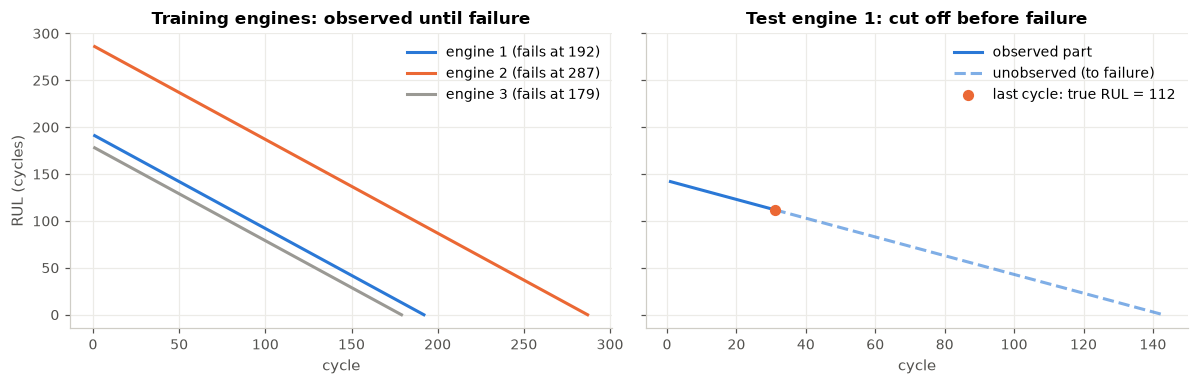

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)

for unit, color in zip([1, 2, 3], [BLUE, ORANGE, GREY]):
    e = train[train["unit"] == unit]
    axes[0].plot(e["cycle"], e["RUL"], color=color, label=f"engine {unit} (fails at {e['cycle'].max()})")
axes[0].set(title="Training engines: observed until failure", xlabel="cycle", ylabel="RUL (cycles)")
axes[0].legend()

e = test[test["unit"] == 1]
end = e["cycle"].max()
axes[1].plot(e["cycle"], e["RUL"], color=BLUE, label="observed part")
future = np.arange(end, end + rul[1] + 1)
axes[1].plot(future, rul[1] - (future - end), color=BLUE, ls="--", alpha=0.6, label="unobserved (to failure)")
axes[1].scatter([end], [rul[1]], color=ORANGE, zorder=3, s=40, label=f"last cycle: true RUL = {rul[1]}")
axes[1].set(title="Test engine 1: cut off before failure", xlabel="cycle")
axes[1].legend()

fig.tight_layout()
save(fig, "01_rul_labels")
plt.show()

## Summary

- FD001 has 20,631 training rows (100 engines run to failure) and 13,096 test rows (100 engines cut before failure).
- The data passed every quality check: nothing is missing or duplicated, and cycles are consecutive in every engine.
- Seven sensors and the operational settings carry no usable information in FD001. We keep **14 sensors**.
- RUL labels are computed per engine. Test engines get a label at every cycle, so error can later be broken down by degradation stage.

Next, notebook 02 looks at how these 14 sensors change as an engine approaches failure.